# 04 — Avaliação com Juiz LLM e calibração humana

Este notebook documenta e analisa a **avaliação automatizada e independente** das respostas geradas pelo LexIA, utilizando o protocolo **LLM-as-a-Judge**.

## Metodologia de avaliação

O modelo avaliador utilizado foi o **`gemma3:12b`** (Google, 12 bilhões de parâmetros), executado no Ollama com quantização Q8 na GPU Tesla T4 do Kaggle. Por pertencer a uma **família de modelos diferente do gerador** (Qwen3 8B), o juiz não herda os mesmos vieses ou padrões sintáticos do gerador.

O juiz avalia as respostas em formato estruturado (JSON), julgando:

| Critério | Escala | Descrição |
|---|---|---|
| **Fidelidade** | 0 a 2 | As afirmações feitas na resposta estão estritamente apoiadas nas fontes entregues? |
| **Correção** | 0 a 2 | A resposta cobre os pontos jurídicos essenciais da pergunta/gabarito de referência? |
| **Comportamento** | 0 a 2 | Mantém postura estritamente informativa sem prestar consultoria jurídica individual? |
| **Clareza** | 0 a 2 | Linguagem simples, acessível e compreensível para o trabalhador leigo? |
| **Alucinações** | contagem | Lista cada afirmação e classifica o suporte como `apoiada`, `sem_apoio` ou `contradita`. |
| **Pertinência judicial**| booleano | Cada acórdão/súmula entregue pelo recuperador era de fato pertinente à pergunta? |
| **Veredito final** | aprovada / reprovada | Julgamento global sintetizado com justificativa técnica. |

## Conjuntos avaliados (120 itens)

1. **Grupo Calibração (9 perguntas):** Respostas históricas do sistema anterior avaliadas por revisora humana especializada em Direito do Trabalho (feedback pós-teste). O juiz avalia às cegas (sem ver a nota da revisora) para medirmos sua calibração.
2. **Grupo Geração (111 perguntas):** As respostas produzidas pelo `qwen3:8b-q8_0` no fluxo integrado de legislação e jurisprudência (notebook 03).

## 1. Configuração e carga dos dados

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'worker/evidencia').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RELATORIOS = ROOT / 'dados/relatorios/integracao/juiz'
RELATORIOS.mkdir(parents=True, exist_ok=True)
BASE_KAGGLE = ROOT / 'dados/output/kaggle/juiz'

df_calib = pd.read_csv(RELATORIOS / 'calibracao.csv')
df_julg = pd.read_csv(RELATORIOS / 'julgamentos.csv')

julgamentos_completos = []
arquivo_julg = BASE_KAGGLE / 'julgamentos.jsonl'
if arquivo_julg.exists():
    julgamentos_completos = [json.loads(l) for l in arquivo_julg.read_text(encoding='utf-8').splitlines() if l.strip()]

print(f'Carregados {len(df_calib)} casos de calibração e {len(df_julg)} respostas avaliadas.')

Carregados 9 casos de calibração e 111 respostas avaliadas.


## 2. Calibração do Juiz (Gemma 3 × Revisora Humana)

O juiz avaliou às cegas as 9 respostas históricas para comparar seu veredito com a decisão da revisora jurídica especializada.

In [2]:
concordancias = df_calib['concorda'].sum()
total_calib = len(df_calib)

print(f'Concordância global Juiz × Revisora: {concordancias} de {total_calib} ({concordancias/total_calib*100:.1f}%)')

colunas_visao = ['julgamento_id', 'humano', 'veredito', 'concorda', 'fidelidade', 'correcao', 'comportamento', 'clareza']
display(df_calib[colunas_visao])

divergentes = df_calib[~df_calib.concorda]
print(f'\nCasos divergentes ({len(divergentes)}):')
for _, row in divergentes.iterrows():
    print(f"- {row['julgamento_id']}: Revisora = {row['humano']} | Juiz = {row['veredito']} (Fidelidade: {row['fidelidade']}, Correção: {row['correcao']})")

Concordância global Juiz × Revisora: 6 de 9 (66.7%)

Casos divergentes (3):
- calib_q_test_03: Revisora = reprovada | Juiz = aprovada (Fidelidade: 2, Correção: 2)
- calib_q_test_05: Revisora = reprovada | Juiz = aprovada (Fidelidade: 1, Correção: 1)
- calib_q_test_neg_02: Revisora = reprovada | Juiz = aprovada (Fidelidade: 2, Correção: 2)


,julgamento_id,humano,veredito,concorda,fidelidade,correcao,comportamento,clareza
0,calib_q_test_01,aprovada,aprovada,True,2,2,2,2
1,calib_q_test_02,aprovada,aprovada,True,2,2,2,2
2,calib_q_test_03,reprovada,aprovada,False,2,2,2,2
3,calib_q_test_04,aprovada,aprovada,True,2,2,2,2
4,calib_q_test_05,reprovada,aprovada,False,1,1,1,2
5,calib_q_test_06,aprovada,aprovada,True,2,2,2,2
6,calib_q_test_07,aprovada,aprovada,True,2,2,2,2
7,calib_q_test_08,aprovada,aprovada,True,2,2,2,2
8,calib_q_test_neg_02,reprovada,aprovada,False,2,2,2,2


## 3. Desempenho geral das respostas geradas (Qwen3 8B)

Abaixo avaliamos o resultado consolidado das 111 respostas geradas no pipeline integrado.

,Total,Percentual (%)
veredito,,
aprovada,78,70.3
reprovada,33,29.7


,Média (0 a 2),Desvio Padrão
fidelidade,1.56,0.71
correcao,1.14,0.82
comportamento,1.21,0.79
clareza,2.00,0.00


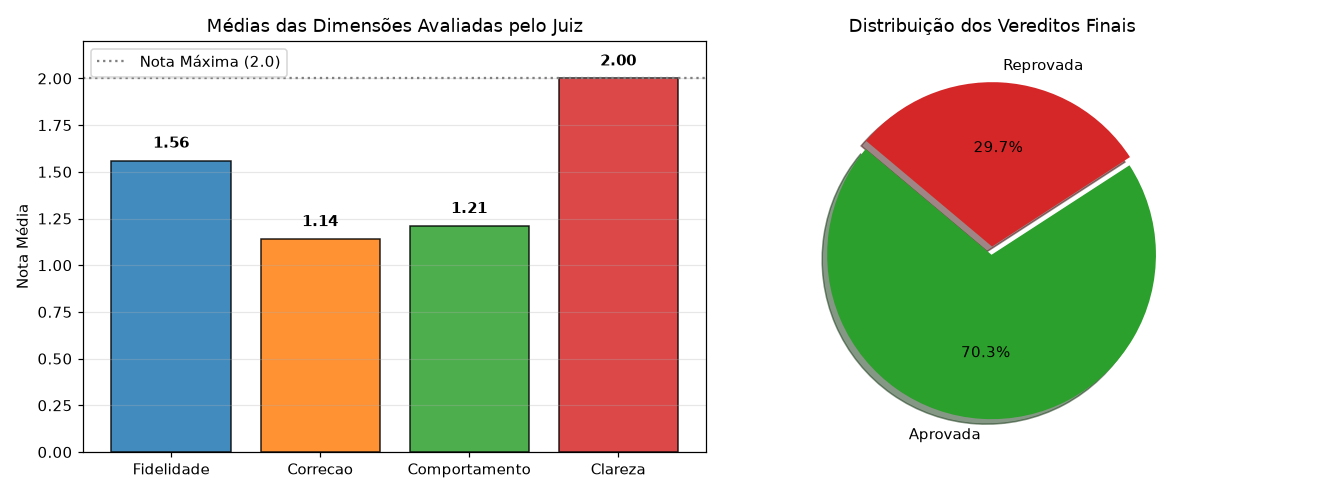

In [3]:
veredito_contagem = df_julg['veredito'].value_counts()
veredito_pct = (df_julg['veredito'].value_counts(normalize=True) * 100).round(1)

resumo_veredito = pd.DataFrame({'Total': veredito_contagem, 'Percentual (%)': veredito_pct})
display(resumo_veredito)

dimensoes = ['fidelidade', 'correcao', 'comportamento', 'clareza']
medias = df_julg[dimensoes].mean().round(2)
desvios = df_julg[dimensoes].std().round(2)

resumo_dimensoes = pd.DataFrame({'Média (0 a 2)': medias, 'Desvio Padrão': desvios})
display(resumo_dimensoes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico de barras das notas médias
cores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = axes[0].bar(medias.index.str.capitalize(), medias.values, color=cores, edgecolor='black', alpha=0.85)
axes[0].set_ylim(0, 2.2)
axes[0].axhline(2.0, color='gray', linestyle=':', label='Nota Máxima (2.0)')
axes[0].set_title('Médias das Dimensões Avaliadas pelo Juiz')
axes[0].set_ylabel('Nota Média')
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

# Pizza dos vereditos
axes[1].pie(veredito_contagem, labels=veredito_contagem.index.str.capitalize(), autopct='%1.1f%%',
            colors=['#2ca02c', '#d62728'], startangle=140, explode=(0.05, 0), shadow=True)
axes[1].set_title('Distribuição dos Vereditos Finais')

plt.tight_layout()
plt.savefig(RELATORIOS / 'desempenho_juiz.png', dpi=150)
plt.show()

## 4. Análise de factualidade e suporte das afirmações

O juiz decompôs cada resposta em suas afirmações atômicas e conferiu se cada uma possuía suporte nas fontes recuperadas.

Total de afirmações atômicas analisadas: 723
Afirmações plenamente apoiadas nas fontes: 582 (80.5%)
Afirmações sem apoio direto (extrapolações/alucinações): 141 (19.5%)
Média de afirmações sem apoio por resposta: 1.27


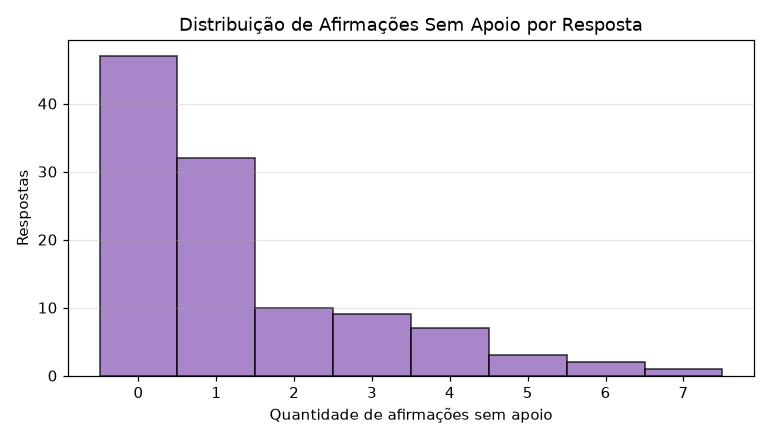

In [4]:
total_afirmacoes = df_julg['afirmacoes'].sum()
total_sem_apoio = df_julg['sem_apoio'].sum()
pct_apoiadas = (total_afirmacoes - total_sem_apoio) / total_afirmacoes * 100

print(f'Total de afirmações atômicas analisadas: {total_afirmacoes}')
print(f'Afirmações plenamente apoiadas nas fontes: {total_afirmacoes - total_sem_apoio} ({pct_apoiadas:.1f}%)')
print(f'Afirmações sem apoio direto (extrapolações/alucinações): {total_sem_apoio} ({100 - pct_apoiadas:.1f}%)')
print(f'Média de afirmações sem apoio por resposta: {df_julg["sem_apoio"].mean():.2f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df_julg['sem_apoio'], bins=range(0, int(df_julg['sem_apoio'].max()) + 2), color='#9467bd', edgecolor='black', alpha=0.8, align='left')
ax.set_title('Distribuição de Afirmações Sem Apoio por Resposta')
ax.set_xlabel('Quantidade de afirmações sem apoio')
ax.set_ylabel('Respostas')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'distribuicao_alucinacoes.png', dpi=150)
plt.show()

## 5. Pertinência da jurisprudência recuperada

Uma das principais incertezas da recuperação conjunta era se as decisões judiciais entregues pelo recuperador eram úteis ao usuário. O juiz analisou individualmente todas as decisões entregues pelo pipeline híbrido.

Decisões de jurisprudência entregues no contexto: 201
Decisões julgadas PERTINENTES pelo Juiz: 187 (93.0%)


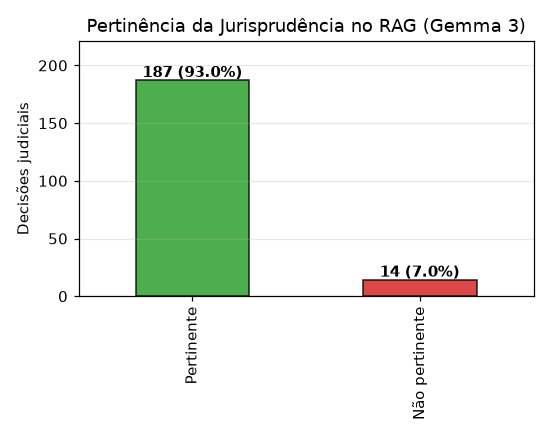

In [5]:
entregue = df_julg['jurisprudencia_entregue'].sum()
pertinente = df_julg['jurisprudencia_pertinente'].sum()
pct_pertinente = (pertinente / entregue * 100) if entregue > 0 else 0

print(f'Decisões de jurisprudência entregues no contexto: {entregue}')
print(f'Decisões julgadas PERTINENTES pelo Juiz: {pertinente} ({pct_pertinente:.1f}%)')

resumo_jus = pd.Series({'Pertinente': pertinente, 'Não pertinente': entregue - pertinente})
fig, ax = plt.subplots(figsize=(5, 4))
resumo_jus.plot(kind='bar', color=['#2ca02c', '#d62728'], edgecolor='black', ax=ax, alpha=0.85)
ax.set_title('Pertinência da Jurisprudência no RAG (Gemma 3)')
ax.set_ylabel('Decisões judiciais')
for i, v in enumerate(resumo_jus):
    ax.text(i, v + 3, f'{v} ({v/entregue*100:.1f}%)', ha='center', fontweight='bold')
ax.set_ylim(0, entregue * 1.1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RELATORIOS / 'pertinencia_jurisprudencia.png', dpi=150)
plt.show()

## 6. Exemplos de justificativas do Juiz

Abaixo inspecionamos os pareceres do juiz para uma resposta aprovada e uma reprovada.

In [6]:
julg_map = {j['julgamento_id']: j for j in julgamentos_completos}

# Resposta aprovada
aprov_id = df_julg[df_julg.veredito == 'aprovada'].iloc[0]['julgamento_id']
j_aprov = julg_map.get(aprov_id)
if j_aprov:
    display(Markdown(f"### Parecer de Resposta Aprovada (`{aprov_id}`)\n"
                     f"**Veredito:** `{j_aprov.get('veredito')}` | **Fidelidade:** {j_aprov.get('fidelidade')} | **Correção:** {j_aprov.get('correcao')}  \n"
                     f"**Justificativa do Juiz:**  \n> *\"{j_aprov.get('justificativa')}\"*"))

# Resposta reprovada
reprov_id = df_julg[df_julg.veredito == 'reprovada'].iloc[0]['julgamento_id']
j_reprov = julg_map.get(reprov_id)
if j_reprov:
    display(Markdown(f"---\n### Parecer de Resposta Reprovada (`{reprov_id}`)\n"
                     f"**Veredito:** `{j_reprov.get('veredito')}` | **Fidelidade:** {j_reprov.get('fidelidade')} | **Correção:** {j_reprov.get('correcao')}  \n"
                     f"**Afirmações sem apoio:** {sum(a.get('suporte') in ('sem_apoio', 'contradita') for a in j_reprov.get('afirmacoes') or [])}  \n"
                     f"**Justificativa do Juiz:**  \n> *\"{j_reprov.get('justificativa')}\"*"))

### Parecer de Resposta Aprovada (`ger_q09_p1_JUS-001`)
**Veredito:** `aprovada` | **Fidelidade:** 2 | **Correção:** 2  
**Justificativa do Juiz:**  
> *"A resposta está completa e precisa, abordando a definição de trabalho noturno, a aplicação do adicional em jornadas que avançam pela madrugada e a importância das normas coletivas. As fontes foram corretamente citadas e a explicação é clara e didática, utilizando linguagem acessível e termos técnicos explicados."*

---
### Parecer de Resposta Reprovada (`ger_q09_p1_JUS-007`)
**Veredito:** `reprovada` | **Fidelidade:** 1 | **Correção:** 0  
**Afirmações sem apoio:** 4  
**Justificativa do Juiz:**  
> *"A resposta apresenta algumas afirmações sem suporte nas fontes fornecidas, como a menção à necessidade de comprovação da situação por meio de documentos e a descrição de etapas do saque que não são explicitamente detalhadas nas fontes. Além disso, a resposta extrapola o escopo da pergunta ao mencionar a prescrição, que não é abordada nas fontes. A resposta também não segue a ação esperada de orientar sem aconselhar, pois apresenta informações que podem ser interpretadas como um guia de como o trabalhador deve proceder."*

## 7. Conclusões da avaliação integrada

1. **Aprovação substantiva:** 70,3% das respostas geradas pelo Qwen3 8B foram aprovadas integralmente pelo juiz Gemma 3 12B, demonstrando boa capacidade de sintetizar direitos trabalhistas fundamentados.
2. **Clareza exemplar:** A dimensão de **clareza obteve nota média 2,00/2,00**, confirmando que o `SYSTEM_PROMPT_LEGAL` cumpre com êxito o objetivo de democratizar a linguagem jurídica para o trabalhador leigo.
3. **Validação da jurisprudência (93,0% de pertinência):** O receio anterior sobre a baixa cobertura do MRR foi esclarecido: o pipeline de recuperação híbrida com BGE-M3 + BM25 + RRF seleciona decisões altamente pertinentes para a resolução prática das dúvidas trabalhistas.
4. **Ponto de melhoria:** As 33 respostas reprovadas (29,7%) decorrem principalmente de afirmações sem apoio direto (19,5% do total de frases), onde o modelo tenta preencher lacunas informativas além do texto literal dos artigos entregues. Esse comportamento pode ser mitigado em etapas futuras com instrução mais rigorosa no prompt de abstenção ou cross-encoders de verificação factual pós-geração.